# Numerai Classic v6.0 ("Unity") — LightGBM Regressor (`NumeraiExtractions` + `LightGBMNumeraiEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, catching each library's actual exception classes (`KaggleApiHTTPError`, `UnauthenticatedError`, `CredentialError`, `NotFoundError`, `DataCorruptionError`, `BackendError`, `KaggleEnvironmentError`, `ColabEnvironmentError`, `kaggle.rest.ApiException`, `HTTPError`, `OSError`, `ValueError`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time (`groupby(ERA_COL)[TARGET_COL].size()`), overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL` along with ADF stationarity checks.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- **`era_col`** (`[ERA_COL]`): Column name containing the sequential weekly time index (`'era'`).
- **`ticker_col`** (`[TICKER_COL]`): Column name containing the security identifier (`'numerai_ticker'`).
- **`target_col`** (`[TARGET_COL, 'target_cyrusd_20', 'target_teager2b_20']`): Target column used when ranking features by target correlation.
- **`year_horizon_filter`** (`[None, (1, 2, 3), (4, 5, 6), (7, 8, 9)]`): Restricts `fit()` variance and correlation estimation to specific 52-week training year buckets `(era - 1) // 52 + 1` (`None` uses all training years; never exposed as a model feature).
- **`variance_threshold`** (`[None, 0.02, 0.05, 0.10]`): Drops near-constant features whose training variance is $\le$ threshold via `sklearn.feature_selection.VarianceThreshold` (`None` keeps all features).
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`):
  - `None`: Skips correlation ranking and keeps original column order.
  - `'pandas_mean'`: Computes per-era Pearson correlation (`era_df.corrwith(era_target)`) and averages across eras.
  - `'numerai_mean'`: Computes official per-era `numerai_tools.scoring.numerai_corr` and averages across eras.
  - `'pearson'`: Global pooled Pearson correlation (`r_regression`) across all rows.
  - `'spearman'`: Global pooled Spearman rank correlation across all rows.
- **`abs_corr`** (`[True, False]`): `True` ranks features by $|\text{corr}|$ (strongest magnitude in either direction); `False` ranks by signed $\text{corr}$ (positive only first).
- **`top_k`** (`[None, 10, 20, 40]`): Keeps only the top $K$ highest-ranked features from the extractor (`None` keeps all features).
- **`feature_selection_percentile`** (`[None, 25.0, 50.0, 75.0, 100.0]`): Keeps the top percentage of ranked features (`None` keeps all features).
- **`sparse_selector`** (`[None, 'lasso', 'elasticnet']`) & **`sparse_alpha`** (`[0.001, 0.01, 0.1]` / `Real(1e-4, 1e-1, prior='log-uniform')`): Optional multivariate sparse feature selection via `sklearn.feature_selection.SelectFromModel` with `Lasso` or `ElasticNet` fitted strictly inside `fit()` (`None` disables).
- **`pca_n_components`** (`[None, 10, 20, 40]` / `0.90`): Optional `sklearn.decomposition.PCA` compression fitted strictly inside `fit()` and quantized to `0..4` `int8` bins in `transform()` to reduce feature exposure without dropping features (`None` disables).
- **`quantize_scope`** (`['era', 'train_fit', 'global']`) & **`quantize_strategy`** (`['zscore', 'quantile']`): Controls how continuous derived features are quantized into `0..4` `int8` bins (`'era'` = leak-free within-era cross-sectional quantization; `'train_fit'` = frozen `StandardScaler` fitted strictly on training data in `fit()`; `'global'` = legacy full-array quantization; `'zscore'` = z-score rounding vs. `'quantile'` = `KBinsDiscretizer` quantile edges).
- **`sequence_top_n`** (`[4, 2, 8]`): Number of top-ranked features expanded by rolling-era, lag-diff, and per-ticker sequence extractors.
- **`missing_fill_value`** (`[2.0, 0.0, 4.0, 'mean', 'median', 'era_mean', 'era_median']`):
  - `2.0`, `0.0`, `4.0`, `'mean'`, `'median'`: Imputes missing values via `sklearn.impute.SimpleImputer` (`2.0` is the neutral middle bin of Numerai's `0..4` scale).
  - `'era_mean'` / `'era_median'`: Fills missing values with each feature's within-era cross-sectional mean or median.
- **`feature_groups`** (`unity_feature_groups` on `NumeraiExtractions`, `None` if no thematic groups exist in `feature_metadata['feature_sets']`; omitted from CV search spaces to prevent console log bloat) & **`basic_group_stats`** (`[None, 'mean', 'std', 'skew', 'mean|std', 'mean|skew', 'std|skew', 'mean|std|skew']`): Computes leak-free row-wise summary statistics (`mean`, `std`, `skew` quantized to `0..4` bins) across real Unity v6.0 feature groups or built-in thematic prefixes (`None` disables).
- **`fourier_period_eras`** (`[52, 26, 13]`): Cycle length in eras (52 = annual, 26 = semi-annual, 13 = quarterly) used by `fourier_order`.
- **`fourier_order`** (`[None, 1, 2, 3]`): Sole cyclical seasonality encoding — adds smooth $\sin(2\pi k \cdot \text{era} / P)$ and $\cos(2\pi k \cdot \text{era} / P)$ harmonics for $k=1..\text{fourier\_order}$ quantized to `0..4` bins (`None` disables).
- **`include_rolling_era`** (`[False, True]`) & **`rolling_era_windows`** (`[(4, 12), (2, 6, 12), (4, 8, 16)]`): When `include_rolling_era=True`, computes causal rolling era means over each window length $W$ in `rolling_era_windows` for the top correlated features, quantized to `0..4` bins.
- **`include_lag_diff`** (`[False, True]`) & **`era_lag_scales`** (`[(1, 2, 4), (1, 2, 4, 8), (2, 4, 8)]`): When `include_lag_diff=True`, computes causal era-to-era lag differences ($\bar{x}_e - \bar{x}_{e-k}$) for each lag step $k$ in `era_lag_scales`, quantized to `0..4` bins.
- **`ticker_features`** (`[None, 'rolling_mean', 'momentum_diff', 'weeks_since_high', 'rolling_rank', 'weeks_since_change', 'expanding_stats', 'raw_lags', 'rolling_mean|momentum_diff', 'rolling_mean|momentum_diff|rolling_rank', 'expanding_stats|raw_lags', 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags']`), **`ticker_windows`** (`[(4, 12), (2, 6, 12)]`), & **`ticker_lag_steps`** (`[None, (1, 2), (1, 2, 4)]`): Computes causal per-ticker time-series features grouped strictly by `numerai_ticker` sorted chronologically by `era` (`None` disables).
- **`era_dispersion_features`** (`[None, 'mean', 'std', 'extreme_frac', 'mean|std', 'mean|extreme_frac', 'std|extreme_frac', 'mean|std|extreme_frac']`): Adds per-row cross-sectional mean (`'mean'`), standard deviation (`'std'`), and fraction of extreme `0`/`4` bins (`'extreme_frac'`) across selected features (`None` disables).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores post-extraction features against `TARGET_COL` (used when `top_k` is set).
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 20, 40, 80]`): Number of top post-extraction features passed to LightGBM (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`): Computes per-row `sample_weight` passed into `LGBMRegressor.fit(...)` (`None`, equal weight per era, linear recency, or exponential recency decay).
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`): Post-prediction within-era normalization (`None` = raw, `'era_zscore'`, or `'era_rank'`).
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).

---

### 3. LightGBM Model Parameters (`lgbm_utils.LightGBMNumeraiEstimator` — `estimator__*`)
- **Boosting & Objective**:
  - **`boosting_type`** (`['gbdt', 'dart', 'rf']`): Gradient boosting decision trees, Dropouts meet Multiple Additive Regression Trees, or Random Forest.
  - **`objective`** (`['regression', 'regression_l1', 'huber', 'fair', 'quantile']`): Loss function (`'regression'` = L2/MSE, `'regression_l1'` = L1/MAE, `'huber'`, `'fair'`, `'quantile'`).
  - **`alpha`** (`[0.9, 0.5, 1.0]` / `Real(0.1, 2.0)`): Huber loss delta or Quantile loss $\alpha$ when `objective` is `'huber'` or `'quantile'`.
  - **`fair_c`** (`[1.0, 0.5, 2.0]` / `Real(0.1, 5.0)`): Scale parameter $c$ when `objective='fair'`.
- **Tree Structure & Learning Schedule**:
  - **`n_estimators`** (`[200, 100, 500, 1000, 2000]` / `Integer(50, 2000)`): Number of boosting rounds (trees).
  - **`learning_rate`** (`[0.05, 0.01, 0.03, 0.1]` / `Real(0.005, 0.15, prior='log-uniform')`): Shrinkage rate per boosting iteration.
  - **`num_leaves`** (`[31, 15, 63, 127]` / `Integer(7, 128)`): Maximum tree leaves for base learners (auto-clamped to $2^{\text{max\_depth}}$ when `max_depth > 0`).
  - **`max_depth`** (`[5, -1, 3, 4, 6, 8]` / `Integer(2, 10)`): Maximum tree depth (`-1` = unlimited).
  - **`extra_trees`** (`[False, True]`): Extremely randomized threshold selection per feature to reduce overfitting.
  - **`linear_tree`** (`[False, True]`) & **`linear_lambda`** (`[0.0, 0.01, 0.1, 1.0]` / `Real(0.0, 5.0)`): Fits piecewise linear models at tree leaves with L2 penalty `linear_lambda`.
- **Leaf Constraints & Regularization**:
  - **`min_split_gain`** (`[0.0, 0.001, 0.01, 0.1]` / `Real(0.0, 0.5)`): Minimum loss reduction required to make a split.
  - **`min_child_weight`** (`[1e-3, 1e-2, 1.0, 10.0]` / `Real(1e-4, 10.0, prior='log-uniform')`): Minimum sum of instance hessian in a leaf.
  - **`min_child_samples`** (`[20, 50, 100, 200]` / `Integer(10, 300)`): Minimum number of rows needed in a leaf (`min_data_in_leaf`).
  - **`reg_alpha`** (`[0.0, 0.01, 0.1, 1.0, 10.0]` / `Real(0.0, 10.0)`): L1 regularization term on leaf weights.
  - **`reg_lambda`** (`[0.0, 0.01, 0.1, 1.0, 10.0]` / `Real(0.0, 10.0)`): L2 regularization term on leaf weights.
  - **`path_smooth`** (`[0.0, 1.0, 10.0, 50.0]` / `Real(0.0, 50.0)`): Hierarchical leaf smoothing toward parent node predictions.
  - **`max_delta_step`** (`[0.0, 0.5, 1.0]` / `Real(0.0, 2.0)`): Limits maximum leaf output magnitude (`0.0` = no constraint).
- **Subsampling & Feature Fraction**:
  - **`subsample`** (`[1.0, 0.8, 0.6]` / `Real(0.5, 1.0)`): Row bagging fraction (`bagging_fraction`).
  - **`subsample_freq`** (`[0, 1, 5]` / `Integer(0, 5)`): Frequency of row bagging (`0` disables; auto-enforced $\ge 1$ for `boosting_type='rf'`).
  - **`colsample_bytree`** (`[0.1, 0.25, 0.5, 0.8, 1.0]` / `Real(0.05, 1.0)`): Fraction of features randomly chosen per tree (`feature_fraction`).
  - **`colsample_bynode`** (`[1.0, 0.5, 0.8]` / `Real(0.3, 1.0)`): Fraction of features randomly chosen at each split node (`feature_fraction_bynode`).
- **Histogram Binning**:
  - **`max_bin`** (`[255, 5, 15, 63]` / `Categorical([5, 15, 63, 255])`): Maximum number of bins for feature bucketing (`5` matches Numerai's native `0..4` int8 bins).
  - **`min_data_in_bin`** (`[3, 5, 10]` / `Integer(1, 20)`): Minimum number of rows inside one histogram bin.
  - **`subsample_for_bin`** (`[200000, 50000, 500000]`): Number of samples used to construct histogram bins.
- **DART Parameters** (active when `boosting_type='dart'`):
  - **`drop_rate`** (`[0.1, 0.05, 0.2]` / `Real(0.01, 0.3)`), **`max_drop`** (`[50, 20, 100]` / `Integer(10, 100)`), **`skip_drop`** (`[0.5, 0.3, 0.7]` / `Real(0.1, 0.9)`), **`xgboost_dart_mode`** (`[False, True]`), **`uniform_drop`** (`[False, True]`).
- **System & Diagnostics**:
  - **`importance_type`** (`['gain', 'split']`), **`feature_pre_filter`** (`[True, False]`), **`force_col_wise`** (`[False, True]`), **`force_row_wise`** (`[False, True]`), **`n_jobs`** (`[lgbm_n_jobs]`), **`lgbm_verbosity`** (`[-1]`).

---

- **Evaluation (`utils.evaluate_numerai_predictions`)**: Reports official `numerai_tools.scoring.numerai_corr`, per-era `Spearman Correlation`, `Average Payout` (`(corrs / 0.2).clip(-1, 1)`), `Sharpe Ratio` (`corrs.mean() / corrs.std()`), `Mean Absolute Error (MAE)`, `Forecast Bias` (`mean(y_true - y_pred)`), `Directional Hit Rate` (sign agreement vs. `0.5`), `Era CORR Lag-1 ACF`, `Ljung-Box p-value` (`acorr_ljungbox`), `ARCH-LM p-value` (`het_arch`), `ADF Stationarity p-value` (`adfuller`), `Skewness`, `Excess Kurtosis`, `Jarque-Bera p-value`, `Max Drawdown`, and validation `Feature Exposure`.

In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
import lightgbm as lgb
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('data_utils.py', 'utils.py', 'baseline_utils.py', 'lgbm_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import data_utils
    import utils
    import baseline_utils
    import lgbm_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py / lgbm_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, src/baseline_utils.py, and src/lgbm_utils.py."
    ) from import_err
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
importlib.reload(lgbm_utils)
from data_utils import compute_per_ticker_timeseries_features, load_unity_numerai_data, load_unity_numerai_data_cached
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    plot_error_bin_waterfall,
    configure_error_binning,
    compute_model_error_bin_comparison,
    compute_error_bin_waterfall,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    prepare_bayesian_space,
    quantize_to_5bins,
    reset_cv_metric_log,
    sharpe_ratio,
    walk_forward_predict,
)
from baseline_utils import BaseNumeraiEstimator, configure_extraction_cache
from lgbm_utils import LightGBMNumeraiEstimator

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | LightGBM={lgb.__version__} | SKOPT_AVAILABLE={SKOPT_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | LightGBM=4.6.0 | SKOPT_AVAILABLE=True


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'all'          # 'small', 'medium', or 'all'
era_stride = 4                 # 1, 2, 4 (20d), or 12 (60d)

search_mode = 'bayes'          # 'grid' or 'bayes'
eval_mode = 'static'             # 'static', 'walk_forward', or 'both'
n_splits = 1
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'within_era'  # None, 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
downsample_frac = 0.05          # Fraction of strided training data to keep in (0.0, 1.0]
n_iter = 5
n_jobs = -1                    # LightGBM thread count (inner CV stays 1 to avoid RAM duplication)
save_results = True
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(
    target_col=TARGET_COL,
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='lightgbm',
    search_mode=search_mode,
    eval_mode=eval_mode,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    n_iter=n_iter,
    n_jobs=1,
    lgbm_n_jobs=n_jobs,
    save_results=save_results,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
)
globals().update(setup_cfg)

Experiment: numerai_v6.0_all_eras_stride4_lightgbm | model=lightgbm | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | horizon=4 | embargo=1 | downsample=within_era@0.05


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 1040 int8 features | train=(54127, 1045) (209 eras) | validation=(2653645, 1045) (398 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
17,2003-01-03,train,006400 KR,2,2,2,1,1,1,1,...,2,2,2,2,2,0,2,2,1.0,1
89,2003-01-03,train,2352 TW,2,2,2,2,2,1,0,...,2,2,2,2,2,0,2,2,1.0,1


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
0,2019-01-04,validation,000030 KR,2,2,2,1,1,1,0,...,0,0,1,1,1,2,0,2,0.5,836
1,2019-01-04,validation,000060 KR,2,2,2,4,4,3,2,...,1,2,2,0,2,1,0,2,0.5,836


Training set info:
<class 'pandas.core.frame.DataFrame'>
Index: 54127 entries, 17 to 4316959
Columns: 1045 entries, date to era
dtypes: float32(1), int32(1), int8(1040), object(3)
memory usage: 55.7+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
Index: 2653645 entries, 0 to 2653644
Columns: 1045 entries, date to era
dtypes: float32(1), int32(1), int8(1040), object(3)
memory usage: 2.7+ GB


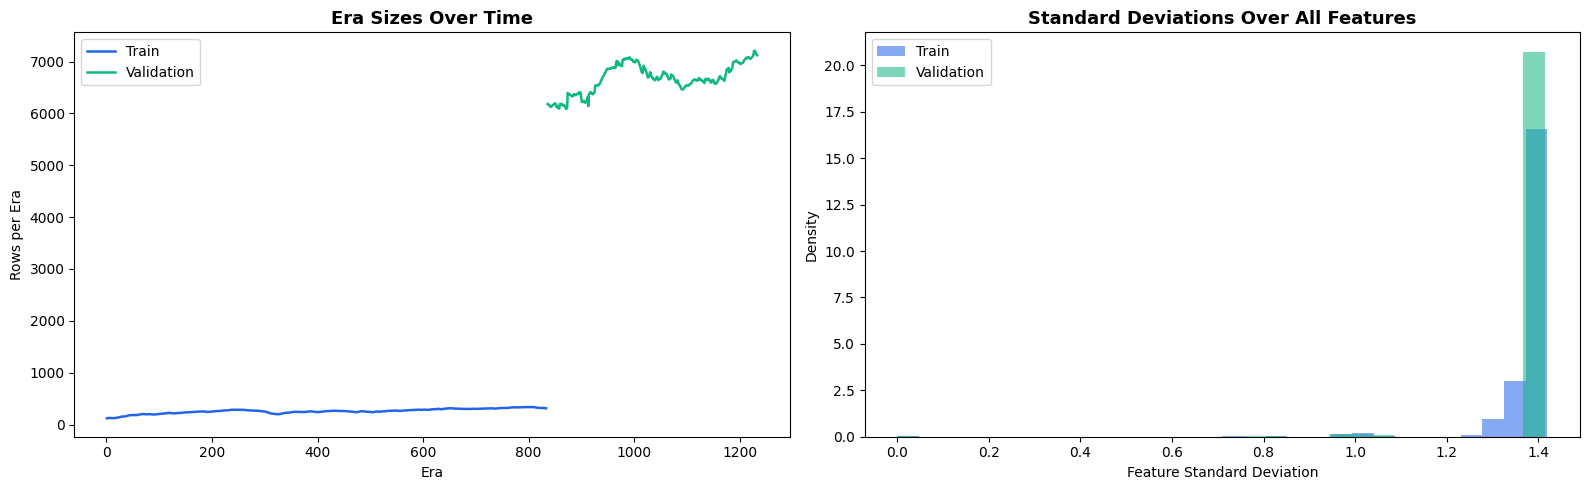

Top 10 Features according to absolute correlation with target:


feature_charisma_69        0.013813
feature_intelligence_34    0.013519
feature_intelligence_37    0.013433
feature_strength_32        0.013280
feature_wisdom_45          0.012963
feature_strength_71        0.012902
feature_constitution_29    0.012857
feature_wisdom_60          0.012702
feature_wisdom_44          0.012453
feature_wisdom_59          0.012443
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_charisma_69,-6.2841,0.0,True
1,feature_intelligence_34,-5.6068,0.0,True
2,feature_intelligence_37,-5.5778,0.0,True
3,feature_strength_32,-5.7667,0.0,True
4,feature_wisdom_45,-5.4978,0.0,True
5,feature_strength_71,-6.9377,0.0,True
6,feature_constitution_29,-7.2206,0.0,True
7,feature_wisdom_60,-6.2760,0.0,True
8,feature_wisdom_44,-5.4172,0.0,True
9,feature_wisdom_59,-6.6693,0.0,True


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].astype(np.float32).std()
val_feat_stds = validation_df[feature_columns].astype(np.float32).std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export and free raw DataFrames (~3.8 GB for feature_set='all')
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
del train_df, validation_df
gc.collect()

# Strictly chronological walk-forward CV splitter (`TimeSeriesSplit` with dynamic `embargo_eras`)
unique_train_eras = np.array(sorted(train_eras.unique()))
if n_splits <= 1:
    split_index = int(len(unique_train_eras) * cv_split)
    era_splits = [(np.arange(0, max(1, split_index - embargo_eras)), np.arange(split_index, len(unique_train_eras)))]
else:
    effective_gap = min(int(embargo_eras), max(0, (len(unique_train_eras) // (n_splits + 1)) - 1))
    era_splits = TimeSeriesSplit(n_splits=n_splits, gap=effective_gap).split(unique_train_eras)
cv_object = [
    (
        np.flatnonzero(train_eras.isin(unique_train_eras[fold_train_eras]).to_numpy()),
        np.flatnonzero(train_eras.isin(unique_train_eras[fold_test_eras]).to_numpy()),
    )
    for fold_train_eras, fold_test_eras in era_splits
]

In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
meta_set_names = {'small', 'medium', 'all'}
active_feature_set_cols = set(feature_columns)
unity_feature_groups_dict = {
    group_name: tuple(col for col in group_cols if col in active_feature_set_cols)
    for group_name, group_cols in raw_feature_sets.items()
    if group_name not in meta_set_names and isinstance(group_cols, list)
}
unity_feature_groups_dict = {k: v for k, v in unity_feature_groups_dict.items() if len(v) >= 2}
unity_feature_groups = tuple(sorted(unity_feature_groups_dict.items())) if unity_feature_groups_dict else None

numerai_extractions = NumeraiExtractions(
    era_col=ERA_COL,
    target_col=TARGET_COL,
    ticker_col=TICKER_COL,
    year_horizon_filter=None,
    variance_threshold=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    top_k=None,
    feature_selection_percentile=None,
    sparse_selector=None,
    sparse_alpha=0.01,
    pca_n_components=None,
    quantize_scope='era',
    quantize_strategy='zscore',
    sequence_top_n=4,
    feature_groups=unity_feature_groups,
    basic_group_stats=None,
    fourier_period_eras=52,
    fourier_order=None,
    rolling_era_windows=(4, 12),
    include_rolling_era=False,
    era_lag_scales=(1, 2, 4),
    include_lag_diff=False,
    ticker_features=None,
    ticker_windows=(4, 12),
    ticker_lag_steps=None,
    era_dispersion_features=None,
    missing_fill_value=2.0,
)

lgbm_estimator = LightGBMNumeraiEstimator(
    extractor=clone(numerai_extractions),
    # BaseNumeraiEstimator shared params
    top_k=None,
    correlation_method=None,
    abs_corr=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
    # LightGBM sklearn API params
    boosting_type='gbdt',
    num_leaves=31,
    max_depth=5,
    learning_rate=0.05,
    n_estimators=200,
    subsample_for_bin=200000,
    objective='regression',
    min_split_gain=0.0,
    min_child_weight=1e-3,
    min_child_samples=20,
    subsample=1.0,
    subsample_freq=0,
    colsample_bytree=0.1,
    reg_alpha=0.0,
    reg_lambda=0.0,
    n_jobs=lgbm_n_jobs,
    importance_type='gain',
    # LightGBM core tree / histogram / regularization / loss / DART params
    max_bin=255,
    min_data_in_bin=3,
    colsample_bynode=1.0,
    extra_trees=False,
    path_smooth=0.0,
    max_delta_step=0.0,
    linear_tree=False,
    linear_lambda=0.0,
    drop_rate=0.1,
    max_drop=50,
    skip_drop=0.5,
    xgboost_dart_mode=False,
    uniform_drop=False,
    alpha=0.9,
    fair_c=1.0,
    feature_pre_filter=True,
    force_col_wise=False,
    force_row_wise=False,
    lgbm_verbosity=lgbm_verbosity,
)

lgbm_pipeline = Pipeline([('estimator', lgbm_estimator)])
print('LightGBM pipeline ready:', lgbm_pipeline)

LightGBM pipeline ready: Pipeline(steps=[('estimator',
                 LightGBMNumeraiEstimator(extractor=NumeraiExtractions(feature_groups=(('signals',
                                                                                        ('feature_adv_20d_factor',
                                                                                         'feature_beta_factor',
                                                                                         'feature_book_to_price_factor',
                                                                                         'feature_dividend_yield_factor',
                                                                                         'feature_earnings_yield_factor',
                                                                                         'feature_growth_factor',
                                                                                         'feature_impact_cost_factor',
                     

# Params

## Grid

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

### LightGBM Model Params (LightGBMNumeraiEstimator)

In [9]:
GRID_PARAM_SPACE_LGBM = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # SHARED PARENT — `BaseNumeraiEstimator` Wrapper Controls
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        None,
        # 'pandas_mean',
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__top_k': [
        None,
        # 20,
        # 40,
        # 80,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],

    # ----------------------------------------------------------
    # MODEL — LightGBM Boosting & Objective
    # ----------------------------------------------------------
    'estimator__boosting_type': [
        'gbdt',
        # 'dart',
        # 'rf',
    ],
    'estimator__objective': [
        'regression',
        # 'regression_l1',
        # 'huber',
        # 'fair',
        # 'quantile',
    ],
    'estimator__alpha': [
        0.9,
        # 0.5,
        # 1.0,
    ],
    'estimator__fair_c': [
        1.0,
        # 0.5,
        # 2.0,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Tree Structure & Learning Schedule
    # ----------------------------------------------------------
    'estimator__n_estimators': [
        200,
        # 100,
        # 500,
        # 1000,
        # 2000,
    ],
    'estimator__learning_rate': [
        0.05,
        # 0.01,
        # 0.03,
        # 0.1,
    ],
    'estimator__num_leaves': [
        31,
        # 15,
        # 63,
        # 127,
    ],
    'estimator__max_depth': [
        5,
        # -1,
        # 3,
        # 4,
        # 6,
        # 8,
    ],
    'estimator__extra_trees': [
        False,
        # True,
    ],
    'estimator__linear_tree': [
        False,
        # True,
    ],
    'estimator__linear_lambda': [
        0.0,
        # 0.01,
        # 0.1,
        # 1.0,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Leaf Constraints & Regularization
    # ----------------------------------------------------------
    'estimator__min_split_gain': [
        0.0,
        # 0.001,
        # 0.01,
        # 0.1,
    ],
    'estimator__min_child_weight': [
        1e-3,
        # 1e-2,
        # 1.0,
        # 10.0,
    ],
    'estimator__min_child_samples': [
        20,
        # 50,
        # 100,
        # 200,
    ],
    'estimator__reg_alpha': [
        0.0,
        # 0.01,
        # 0.1,
        # 1.0,
        # 10.0,
    ],
    'estimator__reg_lambda': [
        0.0,
        # 0.01,
        # 0.1,
        # 1.0,
        # 10.0,
    ],
    'estimator__path_smooth': [
        0.0,
        # 1.0,
        # 10.0,
        # 50.0,
    ],
    'estimator__max_delta_step': [
        0.0,
        # 0.5,
        # 1.0,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Subsampling & Feature Fraction
    # ----------------------------------------------------------
    'estimator__subsample': [
        1.0,
        # 0.8,
        # 0.6,
    ],
    'estimator__subsample_freq': [
        0,
        # 1,
        # 5,
    ],
    'estimator__colsample_bytree': [
        0.1,
        # 0.25,
        # 0.5,
        # 0.8,
        # 1.0,
    ],
    'estimator__colsample_bynode': [
        1.0,
        # 0.5,
        # 0.8,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM Histogram Binning
    # ----------------------------------------------------------
    'estimator__max_bin': [
        255,
        # 5,
        # 15,
        # 63,
    ],
    'estimator__min_data_in_bin': [
        3,
        # 5,
        # 10,
    ],
    'estimator__subsample_for_bin': [
        200000,
        # 50000,
        # 500000,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM DART Controls (Active when boosting_type='dart')
    # ----------------------------------------------------------
    'estimator__drop_rate': [
        0.1,
        # 0.05,
        # 0.2,
    ],
    'estimator__max_drop': [
        50,
        # 20,
        # 100,
    ],
    'estimator__skip_drop': [
        0.5,
        # 0.3,
        # 0.7,
    ],
    'estimator__xgboost_dart_mode': [
        False,
        # True,
    ],
    'estimator__uniform_drop': [
        False,
        # True,
    ],

    # ----------------------------------------------------------
    # MODEL — LightGBM System & Diagnostics
    # ----------------------------------------------------------
    'estimator__importance_type': [
        'gain',
        # 'split',
    ],
    'estimator__feature_pre_filter': [
        True,
        # False,
    ],
    'estimator__force_col_wise': [
        False,
        # True,
    ],
    'estimator__force_row_wise': [
        False,
        # True,
    ],
    'estimator__n_jobs': [lgbm_n_jobs],
    'estimator__lgbm_verbosity': [lgbm_verbosity],
}

## Bayesian

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [10]:
# BAYESIAN SEARCH ONLY — Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE`
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

### LightGBM Model Params (LightGBMNumeraiEstimator)

In [11]:
BAYESIAN_PARAM_SPACE_LGBM = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_PARAM_SPACE_LGBM = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # SHARED PARENT — `BaseNumeraiEstimator` Wrapper Controls
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__top_k': Categorical([
            None,
            20,
            40,
            80,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([
            1,
            2,
            4,
        ]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),

        # ----------------------------------------------------------
        # MODEL — LightGBM Boosting & Objective
        # ----------------------------------------------------------
        'estimator__boosting_type': Categorical(['gbdt']), # dart, rf
        'estimator__objective': Categorical([
            'regression',
            'regression_l1',
            'huber',
            'fair',
            'quantile',
        ]),
        'estimator__alpha': Real(0.1, 2.0),
        'estimator__fair_c': Real(0.1, 5.0),

        # ----------------------------------------------------------
        # MODEL — LightGBM Tree Structure & Learning Schedule
        # ----------------------------------------------------------
        'estimator__n_estimators': Integer(50, 1000),
        'estimator__learning_rate': Real(0.005, 0.15, prior='log-uniform'),
        'estimator__num_leaves': Integer(15, 64),
        'estimator__max_depth': Integer(4, 6),
        'estimator__extra_trees': Categorical([False, True]),
        'estimator__linear_tree': Categorical([False]),
        'estimator__linear_lambda': Real(0.0, 5.0),

        # ----------------------------------------------------------
        # MODEL — LightGBM Leaf Constraints & Regularization
        # ----------------------------------------------------------
        'estimator__min_split_gain': Real(0.0, 0.5),
        'estimator__min_child_weight': Real(1e-4, 10.0, prior='log-uniform'),
        'estimator__min_child_samples': Integer(10, 300),
        'estimator__reg_alpha': Real(0.0, 10.0),
        'estimator__reg_lambda': Real(0.0, 10.0),
        'estimator__path_smooth': Real(0.0, 50.0),
        'estimator__max_delta_step': Real(0.0, 2.0),

        # ----------------------------------------------------------
        # MODEL — LightGBM Subsampling & Feature Fraction
        # ----------------------------------------------------------
        'estimator__subsample': Categorical([0.7]),
        'estimator__subsample_freq': Categorical([1]),
        'estimator__colsample_bytree': Categorical([0.1]),
        'estimator__colsample_bynode': Categorical([0.5]),

        # ----------------------------------------------------------
        # MODEL — LightGBM Histogram Binning
        # ----------------------------------------------------------
        'estimator__max_bin': Categorical([5]),
        'estimator__min_data_in_bin': Integer(1, 20),
        'estimator__subsample_for_bin': Categorical([50000]),

        # ----------------------------------------------------------
        # MODEL — LightGBM DART Controls (Active when boosting_type='dart')
        # ----------------------------------------------------------
        'estimator__drop_rate': Categorical([0.1]),
        'estimator__max_drop': Categorical([50]),
        'estimator__skip_drop': Categorical([0.5]),
        'estimator__xgboost_dart_mode': Categorical([False]),
        'estimator__uniform_drop': Categorical([False]),

        # ----------------------------------------------------------
        # MODEL — LightGBM System & Diagnostics
        # ----------------------------------------------------------
        'estimator__importance_type': Categorical(['gain', 'split']),
        'estimator__feature_pre_filter': Categorical([True, False]),
        'estimator__force_col_wise': Categorical([False, True]),
        'estimator__force_row_wise': Categorical([False, True]),
        'estimator__n_jobs': Categorical([lgbm_n_jobs]),
        'estimator__lgbm_verbosity': Categorical([lgbm_verbosity]),
    }
    BAYESIAN_PARAM_SPACE_LGBM = prepare_bayesian_space(BAYESIAN_PARAM_SPACE_LGBM)

## Active Search Space Validation & Routing

In [12]:
lgbm_param_names = set(lgbm_pipeline.get_params(deep=True))
expected_tunable_params = {
    p for p in lgbm_param_names
    if p.startswith('estimator__') and p not in ('estimator__extractor', 'estimator__extractor__feature_groups', 'estimator__reuse_binned_dataset')
}
assert set(GRID_PARAM_SPACE_LGBM).issubset(lgbm_param_names)
assert expected_tunable_params == set(GRID_PARAM_SPACE_LGBM), (
    f'Missing from GRID_PARAM_SPACE_LGBM: {sorted(expected_tunable_params - set(GRID_PARAM_SPACE_LGBM))}'
)
if SKOPT_AVAILABLE:
    assert set(BAYESIAN_PARAM_SPACE_LGBM).issubset(lgbm_param_names)
    assert expected_tunable_params == set(BAYESIAN_PARAM_SPACE_LGBM), (
        f'Missing from BAYESIAN_PARAM_SPACE_LGBM: {sorted(expected_tunable_params - set(BAYESIAN_PARAM_SPACE_LGBM))}'
    )

if search_mode == 'bayes':
    _pruned_lgbm_bayes = drop_constant_dims(BAYESIAN_PARAM_SPACE_LGBM, lgbm_pipeline)
    lgbm_param_space = build_conditional_bayesian_spaces(_pruned_lgbm_bayes, total_n_iter=n_iter)
else:
    lgbm_param_space = GRID_PARAM_SPACE_LGBM
_active_dim_count = len(set().union(*(sub.keys() for sub, _ in lgbm_param_space))) if isinstance(lgbm_param_space, list) else len(lgbm_param_space)
print(f'Active search_mode={search_mode} | Active LightGBM + Extractor dims={_active_dim_count} (total exposed={len(expected_tunable_params)})')

Active search_mode=bayes | Active LightGBM + Extractor dims=55 (total exposed=78)


# Train

In [13]:
_train_t0 = time.perf_counter()
model_results = {}
search_summary_rows = []
cv_results_by_model = {}
fitted_default_models = {}

effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 2)
    if str(feature_set).strip().lower() in ('medium', 'all')
    else int(extraction_cache_max_entries)
)
configure_extraction_cache(enabled=extraction_cache_enabled, max_entries=effective_cache_max_entries)

model_name = 'LightGBM Regressor'
print(
    f'Running {model_name} inline (lgbm_n_jobs={lgbm_n_jobs}, inner cv_n_jobs=1, '
    f'extraction_cache_max_entries={effective_cache_max_entries})'
)
default_model = clone(lgbm_pipeline).fit(X_train, y_train)
fitted_default_models[model_name] = default_model

train_preds = default_model.predict(X_train)
val_preds = default_model.predict(X_validation)

train_eval = evaluate_numerai_predictions(
    y_train,
    train_preds,
    eras=train_eras,
    features_df=X_train,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Training Scores',
    verbose=True,
)
val_eval = evaluate_numerai_predictions(
    y_validation,
    val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Validation Scores',
    verbose=True,
)

default_variant_name = f'{model_name} [Default]'
if eval_mode in ('static', 'both'):
    model_results[default_variant_name] = {
        'variant': default_variant_name,
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': val_eval['numerai_corr'],
        'validation_corr_pct': val_eval['numerai_corr_pct'],
        'positive_era_pct': val_eval['positive_era_pct'],
        'directional_accuracy_pct': val_eval['directional_accuracy_pct'],
        'validation_spearman': val_eval['spearman'],
        'validation_payout': val_eval['payout'],
        'validation_sharpe': val_eval['numerai_sharpe'],
        'validation_spearman_sharpe': val_eval['spearman_sharpe'],
        'validation_mae': val_eval['mae'],
        'forecast_bias': val_eval['forecast_bias'],
        'directional_hit_rate': val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': val_eval['arch_lm_pvalue'],
        'adf_pvalue': val_eval['adf_pvalue'],
        'era_corr_skew': val_eval['era_corr_skew'],
        'era_corr_kurtosis': val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': val_eval['jarque_bera_pvalue'],
        'feature_exposure': val_eval['feature_exposure'],
        'max_drawdown': val_eval['max_drawdown'],
        'corr_gap': train_eval['numerai_corr'] - val_eval['numerai_corr'],
        'sanity_status': val_eval['sanity_status'],
        'validation_preds': val_preds,
        'validation_era_corrs': val_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

if eval_mode in ('walk_forward', 'both'):
    wf_preds = walk_forward_predict(
        lgbm_pipeline,
        X_train,
        y_train,
        train_eras,
        X_validation,
        y_validation,
        validation_eras,
        step_eras=walk_forward_step_eras,
        window_mode=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=era_stride,
    )
    wf_eval = evaluate_numerai_predictions(
        y_validation,
        wf_preds,
        eras=validation_eras,
        features_df=X_validation,
        feature_columns=feature_columns,
        label=f'{model_name} — Walk-Forward Validation Scores',
        verbose=True,
    )
    wf_variant_name = f'{model_name} [Walk-Forward]'
    model_results[wf_variant_name] = {
        'variant': wf_variant_name,
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': wf_eval['numerai_corr'],
        'validation_corr_pct': wf_eval['numerai_corr_pct'],
        'positive_era_pct': wf_eval['positive_era_pct'],
        'directional_accuracy_pct': wf_eval['directional_accuracy_pct'],
        'validation_spearman': wf_eval['spearman'],
        'validation_payout': wf_eval['payout'],
        'validation_sharpe': wf_eval['numerai_sharpe'],
        'validation_spearman_sharpe': wf_eval['spearman_sharpe'],
        'validation_mae': wf_eval['mae'],
        'forecast_bias': wf_eval['forecast_bias'],
        'directional_hit_rate': wf_eval['directional_hit_rate'],
        'era_corr_lag1_acf': wf_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': wf_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': wf_eval['arch_lm_pvalue'],
        'adf_pvalue': wf_eval['adf_pvalue'],
        'era_corr_skew': wf_eval['era_corr_skew'],
        'era_corr_kurtosis': wf_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': wf_eval['jarque_bera_pvalue'],
        'feature_exposure': wf_eval['feature_exposure'],
        'max_drawdown': wf_eval['max_drawdown'],
        'corr_gap': train_eval['numerai_corr'] - wf_eval['numerai_corr'],
        'sanity_status': wf_eval['sanity_status'],
        'validation_preds': wf_preds,
        'validation_era_corrs': wf_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

if search_mode == 'bayes':
    if not SKOPT_AVAILABLE or BayesSearchCV is None:
        raise ImportError('scikit-optimize is required for Bayesian search')
    lgbm_search_spaces = (
        lgbm_param_space
        if isinstance(lgbm_param_space, list)
        else build_conditional_bayesian_spaces(lgbm_param_space, total_n_iter=n_iter)
    )
    search = BayesSearchCV(
        estimator=lgbm_pipeline,
        search_spaces=lgbm_search_spaces,
        n_iter=n_iter,
        optimizer_kwargs={'base_estimator': 'ET', 'acq_func': 'EI', 'n_initial_points': min(4, max(1, n_iter // 3))},
        scoring=candidate_score,
        cv=cv_object,
        refit=False,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )
else:
    deduped_grid = deduplicate_param_grid(lgbm_param_space, base_params=lgbm_pipeline.get_params(deep=True))
    search = GridSearchCV(
        estimator=lgbm_pipeline,
        param_grid=deduped_grid,
        scoring=candidate_score,
        cv=cv_object,
        refit=False,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )

reset_cv_metric_log()
search.fit(X_train, y_train, groups=train_eras)
cv_results_by_model[model_name] = build_quick_results_df(search)
search_summary_rows.append({
    'model': model_name,
    'search_mode': search_mode,
    'best_cv_corr': float(search.best_score_),
    'best_cv_corr_pct': round(float(search.best_score_) * 100.0, 2),
    'best_params': dict(search.best_params_),
})
train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed LightGBM train + CV in {train_elapsed_s:.1f}s')

Running LightGBM Regressor inline (lgbm_n_jobs=-1, inner cv_n_jobs=1, extraction_cache_max_entries=2)
--- LightGBM Regressor — Final Training Scores ---
Percentage Summary | Numerai CORR: +51.41% | Positive Eras: 100.0% | Directional Accuracy: 77.9%
Numerai CORR: 0.5141
Spearman Correlation: 0.4968
Average Payout: 1.0000
Sharpe Ratio (Numerai / Spearman): 9.1053 / 8.9786
Mean Absolute Error (MAE): 0.1492
Forecast Bias (mean(y - y_hat)): -0.0000
Directional Hit Rate (vs 0.5): 0.7790 (77.9%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: 0.1689 | Ljung-Box p: 0.0000 | ARCH-LM p: 1.0000 | ADF p: 0.0005
Era CORR Tail Risk | Skew: -0.4330 | Excess Kurtosis: 0.1870 | Jarque-Bera p: 0.0361
Feature Exposure: 0.0405
[SANITY WARNING — LIKELY LEAKAGE] numerai_corr=0.5141 > 0.040 ceiling (check for future era/target leakage or in-sample overfitting).
--- LightGBM Regressor — Final Validation Scores ---
Percentage Summary | Numerai CORR: +1.27% | Positive Eras: 82.9% | Directional Accuracy: 50.6%

In [14]:
comparison_columns = [
    'variant',
    'train_corr',
    'validation_corr',
    'validation_corr_pct',
    'positive_era_pct',
    'directional_accuracy_pct',
    'validation_spearman',
    'validation_payout',
    'validation_sharpe',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'max_drawdown',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result[column] for column in comparison_columns} for result in model_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_corr', ascending=False, kind='stable')
    .reset_index(drop=True)
)
best_variant_name = str(comparison_df.loc[0, 'variant'])
best_validation_era_corrs = model_results[best_variant_name]['validation_era_corrs']
best_validation_corr = model_results[best_variant_name]['validation_corr']

print('LightGBM Holdout Validation Comparison (Official Numerai CORR + Tutorial Spearman/Payout/Sharpe/MAE/Feature Exposure):')
display(comparison_df)
print(f'CV Search Summary ({search_mode}, refit=False):')
display(search_summary_df)
print(f'Top Holdout Variant: {best_variant_name}')

LightGBM Holdout Validation Comparison (Official Numerai CORR + Tutorial Spearman/Payout/Sharpe/MAE/Feature Exposure):


,variant,train_corr,validation_corr,validation_corr_pct,positive_era_pct,directional_accuracy_pct,validation_spearman,validation_payout,validation_sharpe,validation_spearman_sharpe,...,ljung_box_pvalue,arch_lm_pvalue,adf_pvalue,era_corr_skew,era_corr_kurtosis,jarque_bera_pvalue,feature_exposure,max_drawdown,corr_gap,sanity_status
0,LightGBM Regressor [Default],0.5141,0.0127,1.27,82.91,50.62,0.0118,0.0592,0.8722,0.8746,...,0.0,1.0,0.0,0.0438,0.4686,0.1782,0.048,0.1613,0.5014,OK


CV Search Summary (bayes, refit=False):


,model,search_mode,best_cv_corr,best_cv_corr_pct,best_params
0,LightGBM Regressor,bayes,0.01083,1.08,"{'estimator__abs_corr': True, 'estimator__alph..."


Top Holdout Variant: LightGBM Regressor [Default]


# Analysis

Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride4_lightgbm_target_bayes/validation_predictions.parquet


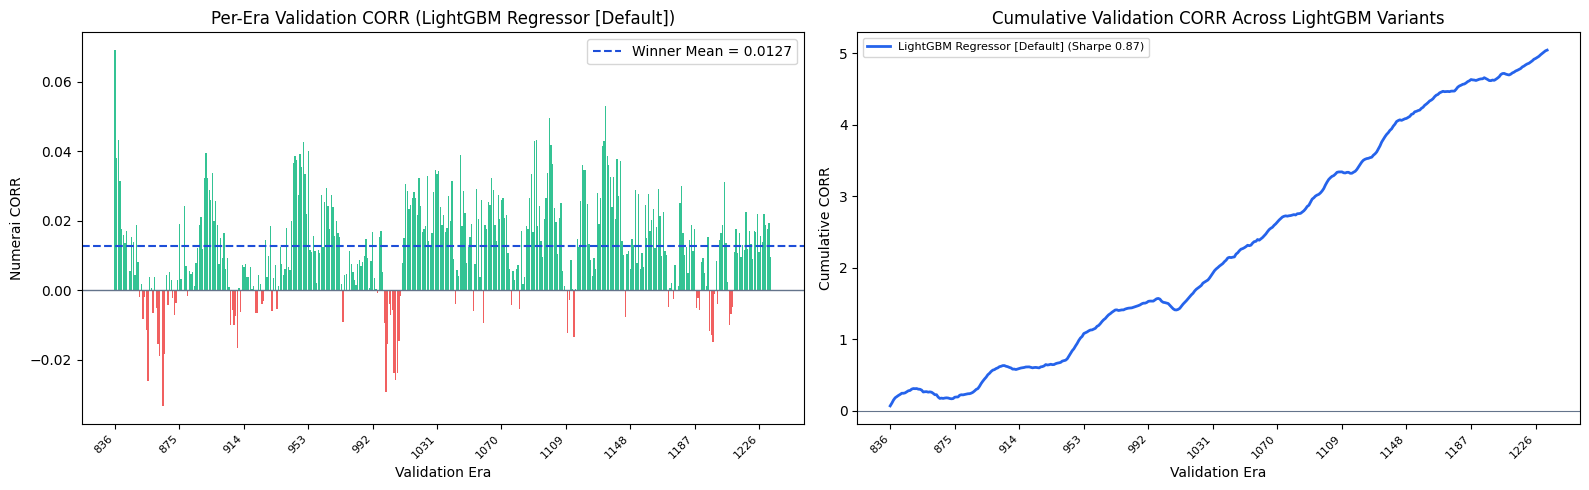

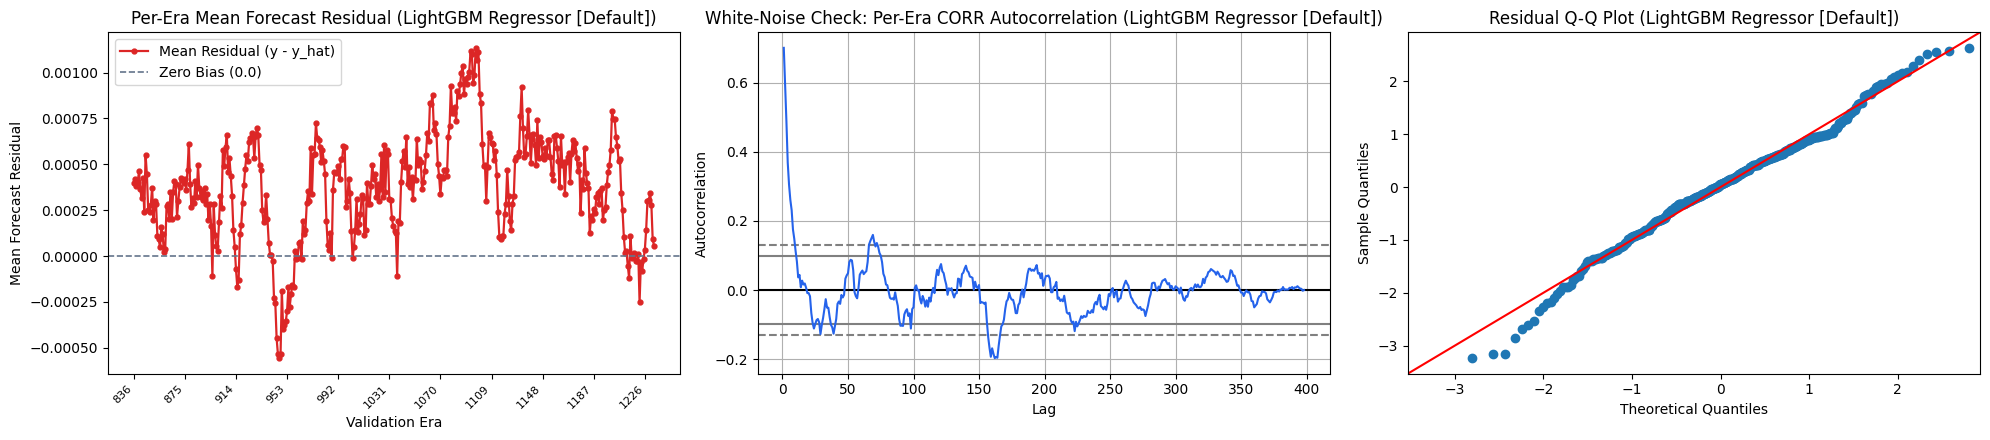

In [15]:
era_positions = np.arange(len(best_validation_era_corrs))
tick_step = max(1, len(best_validation_era_corrs) // 10)
tick_labels = best_validation_era_corrs.index.astype(str)[::tick_step]
line_colors = ['#2563eb', '#10b981', '#f59e0b', '#8b5cf6']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.bar(
    era_positions,
    best_validation_era_corrs.to_numpy(),
    color=['#10b981' if era_corr >= 0 else '#ef4444' for era_corr in best_validation_era_corrs.to_numpy()],
    alpha=0.85,
)
ax.axhline(0.0, color='#64748b', linewidth=1.0)
ax.axhline(best_validation_corr, color='#1d4ed8', linestyle='--', linewidth=1.5, label=f'Winner Mean = {best_validation_corr:.4f}')
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Numerai CORR')
ax.set_title(f'Per-Era Validation CORR ({best_variant_name})')
ax.legend()

ax = axes[1]
for color_index, (variant_name, result) in enumerate(model_results.items()):
    line_color = line_colors[color_index % len(line_colors)]
    ax.plot(
        era_positions,
        result['validation_era_corrs'].cumsum().to_numpy(),
        color=line_color,
        linewidth=2.0,
        label=f"{variant_name} (Sharpe {result['validation_sharpe']:.2f})",
    )
ax.axhline(0.0, color='#64748b', linewidth=0.8)
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Cumulative CORR')
ax.set_title('Cumulative Validation CORR Across LightGBM Variants')
ax.legend(fontsize=8)

plt.tight_layout()
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_era_perf.png', dpi=140)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
    search_summary_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_{search_mode}_summary.csv', index=False)
if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        model_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)
plt.show()

# Brownlee Residual, White-Noise & Tail-Normality Diagnostics (Per-Era Mean Residual + Era CORR Autocorrelation + Residual Q-Q Plot)
winner_val_preds = np.asarray(model_results[best_variant_name]['validation_preds'], dtype=np.float64).ravel()
winner_residuals = pd.Series(y_validation.to_numpy(dtype=np.float64) - winner_val_preds, index=validation_eras.index)
per_era_mean_residuals = winner_residuals.groupby(validation_eras, sort=True).mean()

fig_res, axes_res = plt.subplots(1, 3, figsize=(20, 4.5))
axes_res[0].plot(era_positions, per_era_mean_residuals.to_numpy(), color='#dc2626', marker='o', markersize=3.5, linewidth=1.6, label='Mean Residual (y - y_hat)')
axes_res[0].axhline(0.0, color='#64748b', linestyle='--', linewidth=1.2, label='Zero Bias (0.0)')
axes_res[0].set_xticks(era_positions[::tick_step])
axes_res[0].set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
axes_res[0].set_xlabel('Validation Era')
axes_res[0].set_ylabel('Mean Forecast Residual')
axes_res[0].set_title(f'Per-Era Mean Forecast Residual ({best_variant_name})')
axes_res[0].legend()

if len(best_validation_era_corrs) >= 2:
    autocorrelation_plot(best_validation_era_corrs, ax=axes_res[1], color='#2563eb')
axes_res[1].set_title(f'White-Noise Check: Per-Era CORR Autocorrelation ({best_variant_name})')

if len(per_era_mean_residuals) >= 3:
    qqplot(per_era_mean_residuals.to_numpy(dtype=np.float64), line='45', fit=True, ax=axes_res[2])
axes_res[2].set_title(f'Residual Q-Q Plot ({best_variant_name})')
plt.tight_layout()
if save_results:
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_residual_white_noise.png', dpi=140)
plt.show()

LightGBM Fitted Summary | trees=200 | selected_features=1040 | boosting_type=gbdt | objective=regression


,feature,gain_importance,split_importance,train_corr
0,feature_endurance_7,16.270601,37.0,1.0
1,feature_endurance_9,12.989241,29.0,1.0
2,feature_adv_20d_factor,12.695474,31.0,1.0
3,feature_endurance_8,10.009228,23.0,1.0
4,feature_wisdom_59,9.328598,24.0,1.0
5,feature_charisma_106,9.048322,21.0,1.0
6,feature_endurance_10,8.974415,21.0,1.0
7,feature_constitution_45,8.849338,19.0,1.0
8,feature_charisma_28,8.828230,21.0,1.0
9,feature_intelligence_19,8.722838,21.0,1.0


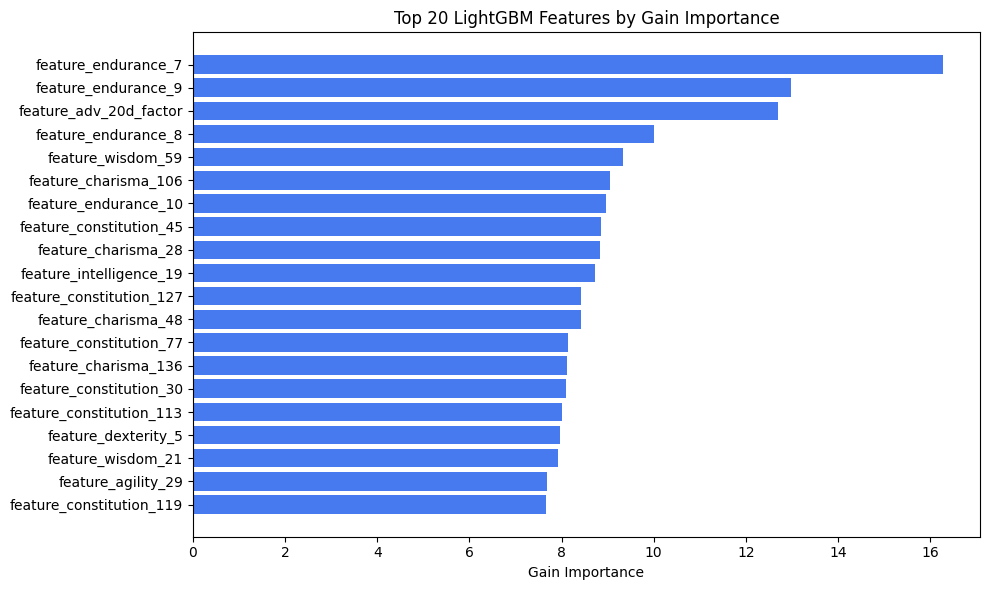

In [16]:
fitted_lgbm = fitted_default_models[model_name].named_steps['estimator']
top_imp_df = fitted_lgbm.feature_importance_df_.head(20)
print(
    f'LightGBM Fitted Summary | trees={fitted_lgbm.model_.booster_.num_trees()} | '
    f'selected_features={len(fitted_lgbm.selected_feature_names_)} | '
    f'boosting_type={fitted_lgbm.boosting_type} | objective={fitted_lgbm.objective}'
)
display(top_imp_df)

if plt is not None and len(top_imp_df):
    plot_imp_df = top_imp_df.sort_values('gain_importance', ascending=True)
    fig_imp, ax_imp = plt.subplots(figsize=(10, 6))
    ax_imp.barh(plot_imp_df['feature'], plot_imp_df['gain_importance'], color='#2563eb', alpha=0.85)
    ax_imp.set_xlabel('Gain Importance')
    ax_imp.set_title('Top 20 LightGBM Features by Gain Importance')
    plt.tight_layout()
    if save_results:
        results_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(results_dir / f'{timestamp}_{experiment_name}_feature_importance.png', dpi=140)
    plt.show()

In [17]:
for cur_model_name, cv_results_df in cv_results_by_model.items():
    print(f'Top CV candidates for {cur_model_name}:')
    display(cv_results_df.head(10))
    if save_results:
        results_dir.mkdir(parents=True, exist_ok=True)
        cv_results_path = results_dir / f'{timestamp}_{experiment_name}_{search_mode}_cv.csv'
        cv_results_df.to_csv(cv_results_path, index=False)
        print('Saved CV results CSV:', cv_results_path)

Top CV candidates for LightGBM Regressor:


,candidate_id,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,mean_test_score,std_test_score,rank_test_score,mean_test_corr_pct,...,num_leaves,objective,path_smooth,prediction_transform,recency_decay,reg_alpha,reg_lambda,top_k,walk_forward_step_eras,walk_forward_window
0,3,48.644839,0.0,6.043458,0.0,0.010830,0.010830,0.0,1,1.08,...,57,huber,5.989190,era_zscore,0.006350,3.315473,2.285717,40.0,NaN,expanding
1,0,7.565879,0.0,6.583538,0.0,0.000000,0.000000,0.0,2,0.00,...,33,regression_l1,13.276992,era_zscore,0.010032,6.385978,3.489362,NaN,NaN,expanding
2,2,21.366796,0.0,66.676999,0.0,0.000000,0.000000,0.0,2,0.00,...,46,quantile,33.402694,era_rank,0.003542,2.503121,5.980812,20.0,20.0,expanding
3,1,10.817543,0.0,57.339142,0.0,-0.007123,-0.007123,0.0,4,-0.71,...,60,regression,3.421046,era_rank,0.002946,1.915149,0.383882,NaN,10.0,sliding
4,4,20.832547,0.0,114.481841,0.0,-0.007673,-0.007673,0.0,5,-0.77,...,31,fair,2.166847,None,0.005122,2.658246,3.505974,20.0,10.0,expanding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride4_lightgbm_target_bayes/20261124_013441_numerai_v6.0_all_eras_stride4_lightgbm_bayes_cv.csv


## Error-Direction Envelope Analysis (All Variants — Best Highlighted)

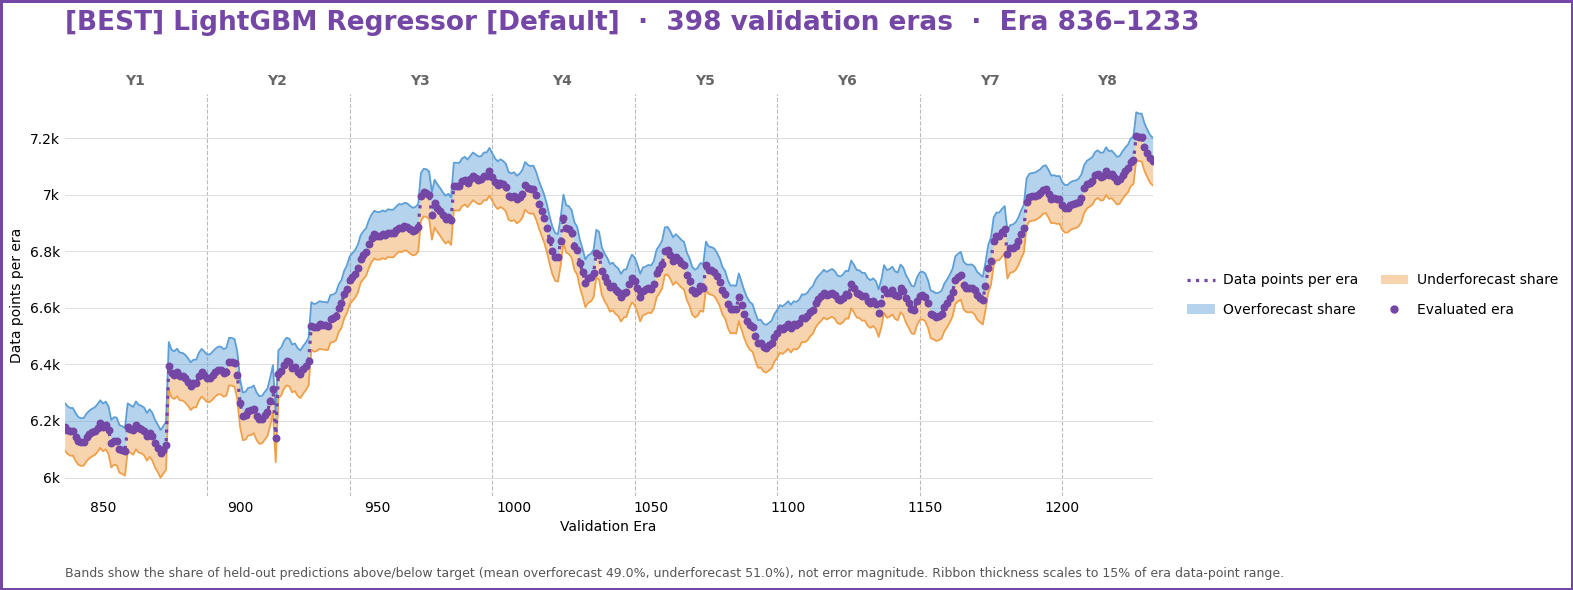

Best Model Envelope Summary (LightGBM Regressor [Default]):


,data_points,under_share,over_share,mae,mean_residual,is_interpolated
era,,,,,,
836,6180,0.500324,0.499676,0.155706,-0.000397,False
837,6169,0.503647,0.496353,0.155871,-0.000419,False
838,6163,0.509168,0.490832,0.155850,-0.000380,False
839,6163,0.509005,0.490995,0.155799,-0.000405,False
840,6144,0.505046,0.494954,0.155751,-0.000462,False
841,6130,0.503752,0.496248,0.156035,-0.000364,False
842,6126,0.505060,0.494940,0.156081,-0.000314,False
843,6127,0.503019,0.496981,0.155969,-0.000423,False
844,6143,0.505616,0.494384,0.156299,-0.000238,False


In [18]:
envelope_dfs = {}
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_results
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        model_results[variant_name]['validation_preds'],
        validation_eras,
        title=variant_name,
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
print(f'Best Model Envelope Summary ({best_variant_name}):')
display(envelope_df.head(10))

## Error-Bin Waterfall & Financial Quarter Breakdown

Overall Error-Bin Comparison Across Evaluated Models:


,variant,data_points,extreme_underforecast_pct,underforecast_pct,accurate_pct,overforecast_pct,extreme_overforecast_pct,net_bias_pct,extreme_total_pct,mae
0,[BEST] LightGBM Regressor [Default],2653645,25.09,2.94,44.23,2.64,25.09,-0.3,50.19,0.1562


Error-Bin Waterfall Summary Table (LightGBM Regressor [Default]):


,section,period,eras,data_points,extreme_underforecast_pct,underforecast_pct,accurate_pct,overforecast_pct,extreme_overforecast_pct,net_bias_pct,extreme_total_pct,mae
0,Overall,Overall (All Validation),398,2653645,25.09,2.94,44.23,2.64,25.09,-0.30,50.19,0.1562
1,Quarterly Avg,Quarterly Avg (31 Qtrs),13,85601,25.09,2.94,44.23,2.64,25.09,-0.31,50.19,0.1562
2,Seasonal Avg,Q1 Avg (8 yrs),13,85597,25.09,2.95,44.16,2.70,25.10,-0.24,50.20,0.1562
3,Seasonal Avg,Q2 Avg (8 yrs),13,86571,25.11,2.92,44.18,2.70,25.09,-0.23,50.20,0.1562
4,Seasonal Avg,Q3 Avg (8 yrs),12,82615,25.09,2.96,44.27,2.58,25.10,-0.38,50.19,0.1562
5,Seasonal Avg,Q4 Avg (7 yrs),13,87912,25.09,2.94,44.34,2.56,25.08,-0.38,50.17,0.1562
6,Financial Quarter,2019-Q1,13,80002,25.10,2.80,44.42,2.57,25.11,-0.22,50.21,0.1560
7,Financial Quarter,2019-Q2,13,79915,25.12,2.92,44.11,2.77,25.08,-0.19,50.20,0.1564
8,Financial Quarter,2019-Q3,13,80067,25.11,2.97,44.29,2.56,25.08,-0.45,50.19,0.1564
9,Financial Quarter,2019-Q4,13,82594,25.10,2.94,44.34,2.52,25.10,-0.43,50.20,0.1562


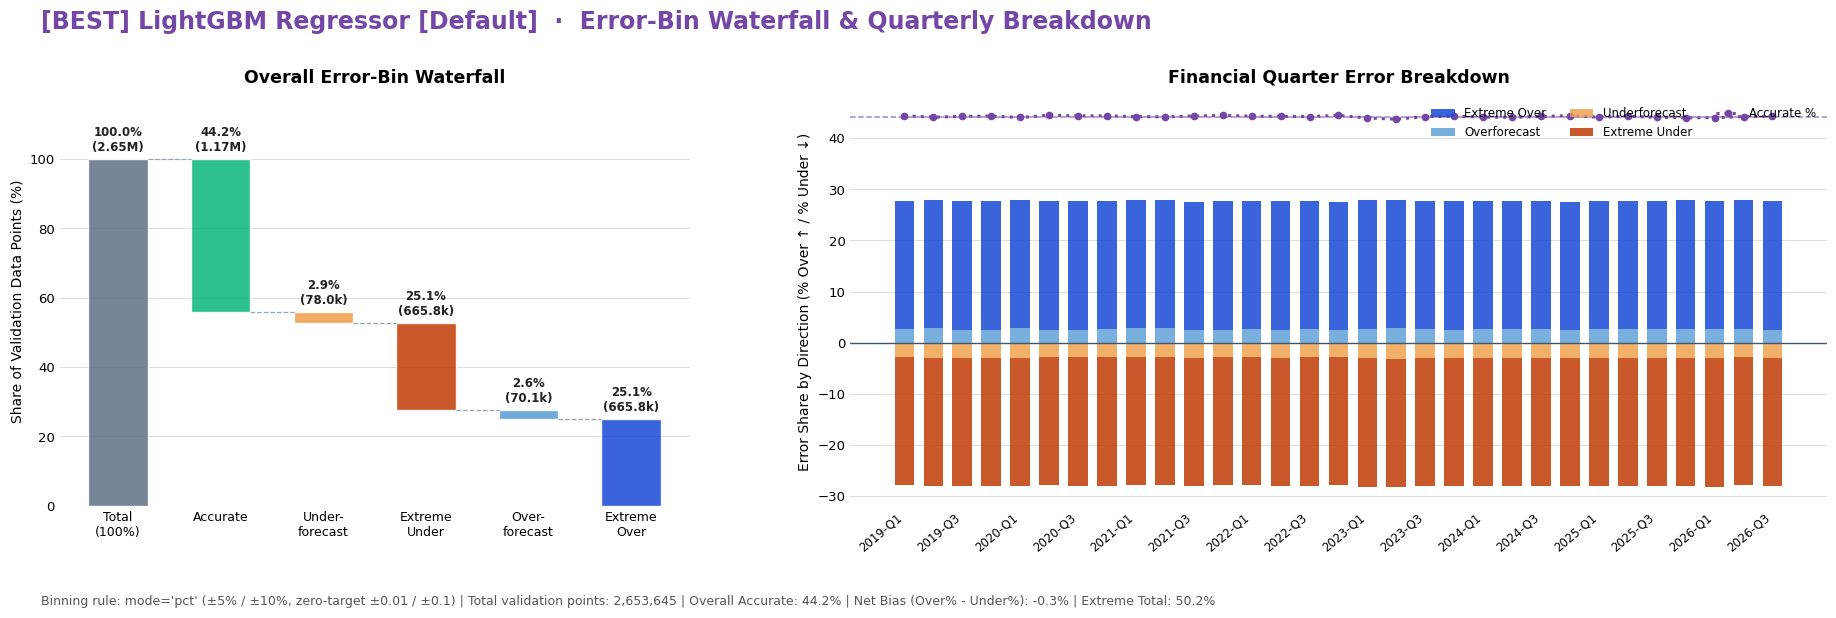

Saved Error-Bin Waterfall CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride4_lightgbm_target_bayes/20261124_013441_numerai_v6.0_all_eras_stride4_lightgbm_error_bin_waterfall.csv


In [19]:
val_dates = val_diag_meta['date'] if 'date' in val_diag_meta.columns else None
model_error_bin_comparison_df = compute_model_error_bin_comparison(
    model_results,
    y_validation,
    best_variant_name=best_variant_name,
    mode=error_bin_mode,
    pct_bins=error_pct_bins,
    zero_tols=error_zero_tols,
    abs_bins=error_abs_bins,
)
print('Overall Error-Bin Comparison Across Evaluated Models:')
display(model_error_bin_comparison_df)

waterfall_df = compute_error_bin_waterfall(
    y_validation,
    model_results[best_variant_name]['validation_preds'],
    validation_eras,
    dates=val_dates,
    mode=error_bin_mode,
    pct_bins=error_pct_bins,
    zero_tols=error_zero_tols,
    abs_bins=error_abs_bins,
)
print(f'Error-Bin Waterfall Summary Table ({best_variant_name}):')
display(waterfall_df)

waterfall_png_path = (
    results_dir / f'{timestamp}_{experiment_name}_error_bin_waterfall.png'
    if save_results
    else None
)
plot_error_bin_waterfall(
    waterfall_df,
    title=best_variant_name,
    save_path=waterfall_png_path,
)
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    waterfall_csv_path = results_dir / f'{timestamp}_{experiment_name}_error_bin_waterfall.csv'
    waterfall_df.to_csv(waterfall_csv_path, index=False)
    model_error_bin_comparison_df.to_csv(
        results_dir / f'{timestamp}_{experiment_name}_model_error_bins.csv', index=False
    )
    print('Saved Error-Bin Waterfall CSV:', waterfall_csv_path)

## Optional Experiment Tracking (Weights & Biases)

In [20]:
if use_wandb:
    if wandb is None:
        print('Skipping W&B logging: wandb is not installed.')
    else:
        wandb_run = wandb.init(
            project=wandb_project,
            name=experiment_name,
            config={
                'data_version': data_version,
                'era_tag': era_tag,
                'model_tag': model_tag,
                'TARGET_COL': TARGET_COL,
                'feature_set': feature_set,
                'era_stride': era_stride,
                'search_mode': search_mode,
                'cv_strategy': cv_strategy,
                'n_splits': n_splits,
                'cv_split': cv_split,
                'downsample_mode': downsample_mode,
                'downsample_frac': downsample_frac,
                'target_horizon_eras': target_horizon_eras,
                'embargo_eras': embargo_eras,
                'eval_mode': eval_mode,
                'walk_forward_step_eras': walk_forward_step_eras,
                'walk_forward_window': walk_forward_window,
                'era_weighting': era_weighting,
                'recency_decay': recency_decay,
                'random_state': random_state,
                'n_iter': n_iter,
                'verbose': verbose,
                'n_jobs': n_jobs,
                'lgbm_n_jobs': lgbm_n_jobs,
                'error_bin_mode': error_bin_mode,
            },
        )
        log_payload = {
            'comparison_table': wandb.Table(dataframe=comparison_df),
            'search_summary_table': wandb.Table(dataframe=search_summary_df.drop(columns=['best_params'], errors='ignore')),
            'timing/prep_elapsed_s': float(prep_elapsed_s),
            'timing/train_elapsed_s': float(train_elapsed_s),
        }
        for m_name, m_cv_df in cv_results_by_model.items():
            m_slug = m_name.lower().replace(' ', '_')
            log_payload[f'cv_table/{m_slug}'] = wandb.Table(dataframe=m_cv_df.astype(str))
        for row in search_summary_rows:
            m_slug = row['model'].lower().replace(' ', '_')
            log_payload[f'best_cv_corr/{m_slug}'] = float(row['best_cv_corr'])
        wandb.log(log_payload)
        wandb.finish()
        print('Logged experiment tables and metrics to Weights & Biases.')
else:
    print('W&B tracking disabled (use_wandb=False).')

W&B tracking disabled (use_wandb=False).
